In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

Загрузка данных

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print("Размер X:", X.shape)
print("Размер y:", y.shape)
print("Классы:", iris.target_names)

Размер X: (150, 4)
Размер y: (150,)
Классы: ['setosa' 'versicolor' 'virginica']


Разделение на обучающую и тестовую выборки


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (120, 4)
Тестовая выборка: (30, 4)


Создание и обучение базовых моделей

In [4]:
models = {
    "логистическая регрессия": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "k ближайших соседей (k=5)": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "дерево решений (без ограничения)": DecisionTreeClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "— модель обучена")

логистическая регрессия — модель обучена
k ближайших соседей (k=5) — модель обучена
дерево решений (без ограничения) — модель обучена


Оценка качества базовых моделей

In [5]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results.append({"Алгоритм": name, "Accuracy": acc})
    print("\n===", name, "===")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print("\n=== Сводная таблица (базовые модели) ===")
print(results_df.to_string(index=False))


=== логистическая регрессия ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


=== k ближайших соседей (k=5) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


=== дерево решений (без ограничения) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       

Задание 1

In [7]:
print("Задание 1: сравнение k")
k_results = []
for k in [3, 5, 7]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    k_results.append({"k": k, "Accuracy": acc})
    print(f"\nk = {k}: accuracy = {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

print(pd.DataFrame(k_results).to_string(index=False))

Задание 1: сравнение k

k = 3: accuracy = 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


k = 5: accuracy = 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


k = 7: accuracy = 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91     

Задание 2

In [12]:
print("Задание 2: глубина дерева")
tree_results = []
for depth in [2, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    label = f"max_depth={depth}" if depth else "без ограничения"
    tree_results.append({"Дерево": label, "Accuracy": acc})
    print(f"\n{label}: accuracy = {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

print(pd.DataFrame(tree_results).to_string(index=False))

Задание 2: глубина дерева

max_depth=2: accuracy = 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


без ограничения: accuracy = 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

         Дерево  Accuracy
    max_depth=2  0.933333
без ограничения  0.933333


Задание 3

In [9]:
print("Задание 3: итоговая таблица трёх алгоритмов")
final = pd.DataFrame([
    {"Алгоритм": "Логистическая регрессия", "Accuracy": results[0]["Accuracy"]},
    {"Алгоритм": "kNN (k=5)",               "Accuracy": results[1]["Accuracy"]},
    {"Алгоритм": "Дерево решений",          "Accuracy": results[2]["Accuracy"]},
]).sort_values("Accuracy", ascending=False)
print(final.to_string(index=False))

Задание 3: итоговая таблица трёх алгоритмов
               Алгоритм  Accuracy
Логистическая регрессия  0.933333
              kNN (k=5)  0.933333
         Дерево решений  0.933333


Задание 4

In [10]:
print("Задание 4: сравнение с MLP")
mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42)
)
mlp.fit(X_train, y_train)
y_pred_mlp = mlp.predict(X_test)
acc_mlp = accuracy_score(y_test, y_pred_mlp)
print(f"MLP accuracy = {acc_mlp:.4f}")
print(classification_report(y_test, y_pred_mlp, target_names=iris.target_names))

all_models = pd.DataFrame([
    {"Модель": "Логистическая регрессия", "Accuracy": results[0]["Accuracy"]},
    {"Модель": "kNN (k=5)",               "Accuracy": results[1]["Accuracy"]},
    {"Модель": "Дерево решений",          "Accuracy": results[2]["Accuracy"]},
    {"Модель": "MLP (16-8)",              "Accuracy": acc_mlp},
]).sort_values("Accuracy", ascending=False)
print("\n=== Итоговое сравнение всех моделей ===")
print(all_models.to_string(index=False))

Задание 4: сравнение с MLP
MLP accuracy = 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


=== Итоговое сравнение всех моделей ===
                 Модель  Accuracy
             MLP (16-8)  0.966667
Логистическая регрессия  0.933333
              kNN (k=5)  0.933333
         Дерево решений  0.933333


Матрица ошибок для выбранной модели

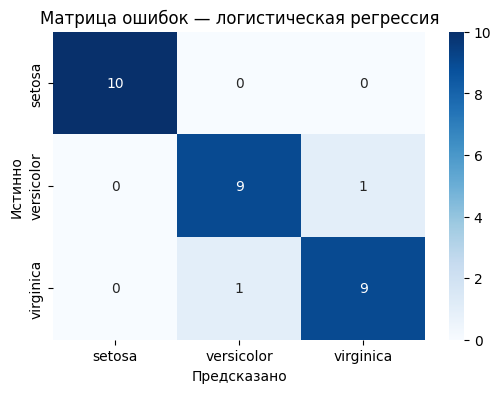

In [11]:
best_model = models["логистическая регрессия"]
y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Предсказано")
plt.ylabel("Истинно")
plt.title("Матрица ошибок — логистическая регрессия")
plt.show()